In [2]:
import os
import sys
import itertools

import joblib
import pandas as pd
import numpy as np
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.plotting import plot_movement_data
from utils.metrics import movement_level_confusion
from utils.constants import Configs
from utils.helper_functions import load_outlier_data
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.lof_detector import LOFDetector
from utils.helper_functions import calculate_trash_percentage
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.feature_selection import make_corr_filter

TARGET_MOVEMENT = 'Park'
ALGORITHM_NAME = 'LOF' 
MODEL_REPRESENTATION = 'FeatureBased'

EXTRACT_SCORES = True

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [3]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=Configs.KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

In [4]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[Configs.KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)
print(f"Number of movements: {n_movements}")

Number of movements: 185


In [5]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=Configs.KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=Configs.KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[Configs.KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[Configs.KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
GT L: 1 positivos / 185 movimentos = 0.54%
GT R: 3 positivos / 185 movimentos = 1.62%
GT OR: 4 positivos / 185 movimentos = 2.16%


### Load Features from Csv

In [6]:
cache_path = Configs.wrist_only_feature_extraction_features(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Features for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")

features_df = joblib.load(cache_path)
features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)
X_features = features_df[Configs.FEATURE_COLS].to_numpy()
n_movements_f = len(features_df)
total_trials = features_df.drop_duplicates(subset=['sub', 'repID']).shape[0]

assert not np.isnan(X_features).any(), "NaN in features"
assert len(features_df) == n_movements, (len(features_df), n_movements)
assert set(map(tuple, features_df[Configs.KEYS].values)) == base_keys
print(X_features.shape)

(185, 43)


## Local Outlier Factor (LOC)

In [7]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

# Ground truth used for evalution on this run
GT_KEY = 'OR'  # TODO isto vai ter de ficar noutro local, mas por agora é só para testar
gt_used = GT[GT_KEY]
total_known_outliers = len(gt_used)

# Movement-level anomalies
known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
known_percentage = known_outlier_rate * 100

# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")
print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")

Phase: Park
positives by ground truth: {'L': 1, 'R': 3, 'OR': 4}
GT used (Union): 4 positives / 185 movements = 2.16%


### Grid Search

In [ ]:
n_neighbors_options = [3, 5, 7, 10, 15, 20]


param_grid = [
    {'n_neighbors': n, 'contamination': s} 
    for n, s in itertools.product(n_neighbors_options, Configs.CONTAMINATION_GRID)
]

loso_results = run_loso_evaluation(
    detector_class=LOFDetector, 
    param_grid=param_grid,
    data_matrix=X_features,                     # all features
    metadata_df=features_df[Configs.META_COLS], # same rows as X_features
    known_outliers_df=gt_used,
    metric_type='euclidean',
    scale_features=True,
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    feature_filter=make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP),
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

LOSO Cross-Validation with 19 subjects (4 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 

### Statistic Evaluation - Bootstraping

In [9]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [10]:
append_experiment_record(
    summary_path=Configs.loso_model_summary_path(MODEL_REPRESENTATION, GT_KEY),
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=n_movements,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for LOF - FeatureBased - Park - 185 Movements (MOVEMENT-level):
Unique Outliers Detected: 18
Rejection Rate: 9.73%
Known Positives in Ground Truth: 4
------------------------------
Total True Positives (Global):  3
Total False Positives (Global): 15
Total False Negatives (Global): 1
Total True Negatives (Global):  166
------------------------------
Blind Precision: 16.67 [0.00–33.33]
Blind Recall:    75.00 [0.00–100.00]
Blind F1-Score:  27.27
Blind F2-Score:  44.12 [0.00–66.04]
Blind MCC:       0.33 [-0.02–0.52]
Blind AUPRC:  37.80 [8.27–100.00]
Blind AUROC:   94.06

Total Tuning Time (19 Subjects): 33.0729s
Total Inference Time (19 Subjects): 0.0629s

Overall Best Parameters (Most frequent across folds):
   {'contamination': 0.08, 'n_neighbors': 10}
Occurrences: 5


### Train Model

In [ ]:
best_params = loso_results['Best_Params']
n_neighbors = best_params['n_neighbors']
contamination = best_params['contamination']

final_filter = make_corr_filter(Configs.FEATURE_COLS, Configs.FEATURES_CORRELATION_THRESHOLD, Configs.PREFER_DROP)
X_final, dropped = final_filter(X_features, np.arange(len(X_features)))
print("Dropped features:", dropped)

X_features_scaled_full = StandardScaler().fit_transform(X_final)

Dropped features: ['max_acc', 'path_length', 'peak_time_diff', 'vel_skewness']


In [12]:
lof_model = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination, n_jobs=-1, metric='euclidean')

# Train mode (oultier = -1, normal = 1)
labels = lof_model.fit_predict(X_features_scaled_full)
features_df['anomaly'] = labels

joblib.dump(lof_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

['/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/SmartRetail_DTW/cache/models/final_model_labels_LOF_FeatureBased_Park.pkl']

In [13]:
# Results
n_outliers = (features_df['anomaly'] == -1).sum()
outliers_details = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

total_trials = features_df.shape[0]
n_unique_outliers, correct_trash_pct = calculate_trash_percentage(features_df, total_trials)
print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Percentagem de Lixo Detetado (sub + repID + movID): {(n_outliers/total_trials*100):.2f}%")
print(f"Percentagem de Lixo Detetado (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 15
Unique Outlier Trials Detected: 15
Percentagem de Lixo Detetado (sub + repID + movID): 8.11%
Percentagem de Lixo Detetado (sub + repID): 8.11%


In [14]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outliers_details.index, cols_to_extract].copy()
print("Quem são os outliers reais?")
print(outliers_metadata_df)

Quem são os outliers reais?
     sub  repID  movID
1      1      2      9
8      2      4      9
10     3      1      9
44     9      5      9
45    10      1      9
46    10      2      9
47    10      3      9
52    11      3      9
75    13      1      9
76    13      2      9
90    15      2     10
112   16      2     12
127   17      1     11
146   18      1     10
151   18      2     11


In [15]:
identified_unique = outliers_metadata_df.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = movement_level_confusion(features_df, np.where(labels == -1)[0], gt_used, Configs.KEYS)

TP=3 FP=12 FN=1 TN=169 | P=20.00% R=75.00% F2=48.39% MCC=0.36


In [16]:
outlier_ids = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

# Create a "unique key" to facilitate filtering
features_df['key'] = features_df['sub'].astype(str) + '_' + features_df['repID'].astype(str) + '_' + features_df['movID'].astype(str)
outlier_keys = features_df[features_df['anomaly'] == -1]['key'].tolist()

# Return to the original DataFrame for plotting
# Create a temporary key in the original df as well
df['temp_key'] = df['sub'].astype(str) + '_' + df['repID'].astype(str) + '_' + df['movID'].astype(str)

# Separate visually
# Note: This is only for plotting; it does not permanently alter the original df if you do not want it to
df_outliers = df[df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]
df_clean = df[~df['temp_key'].isin(outlier_keys) & (df['movLabel'] == TARGET_MOVEMENT)]


### Plot Things

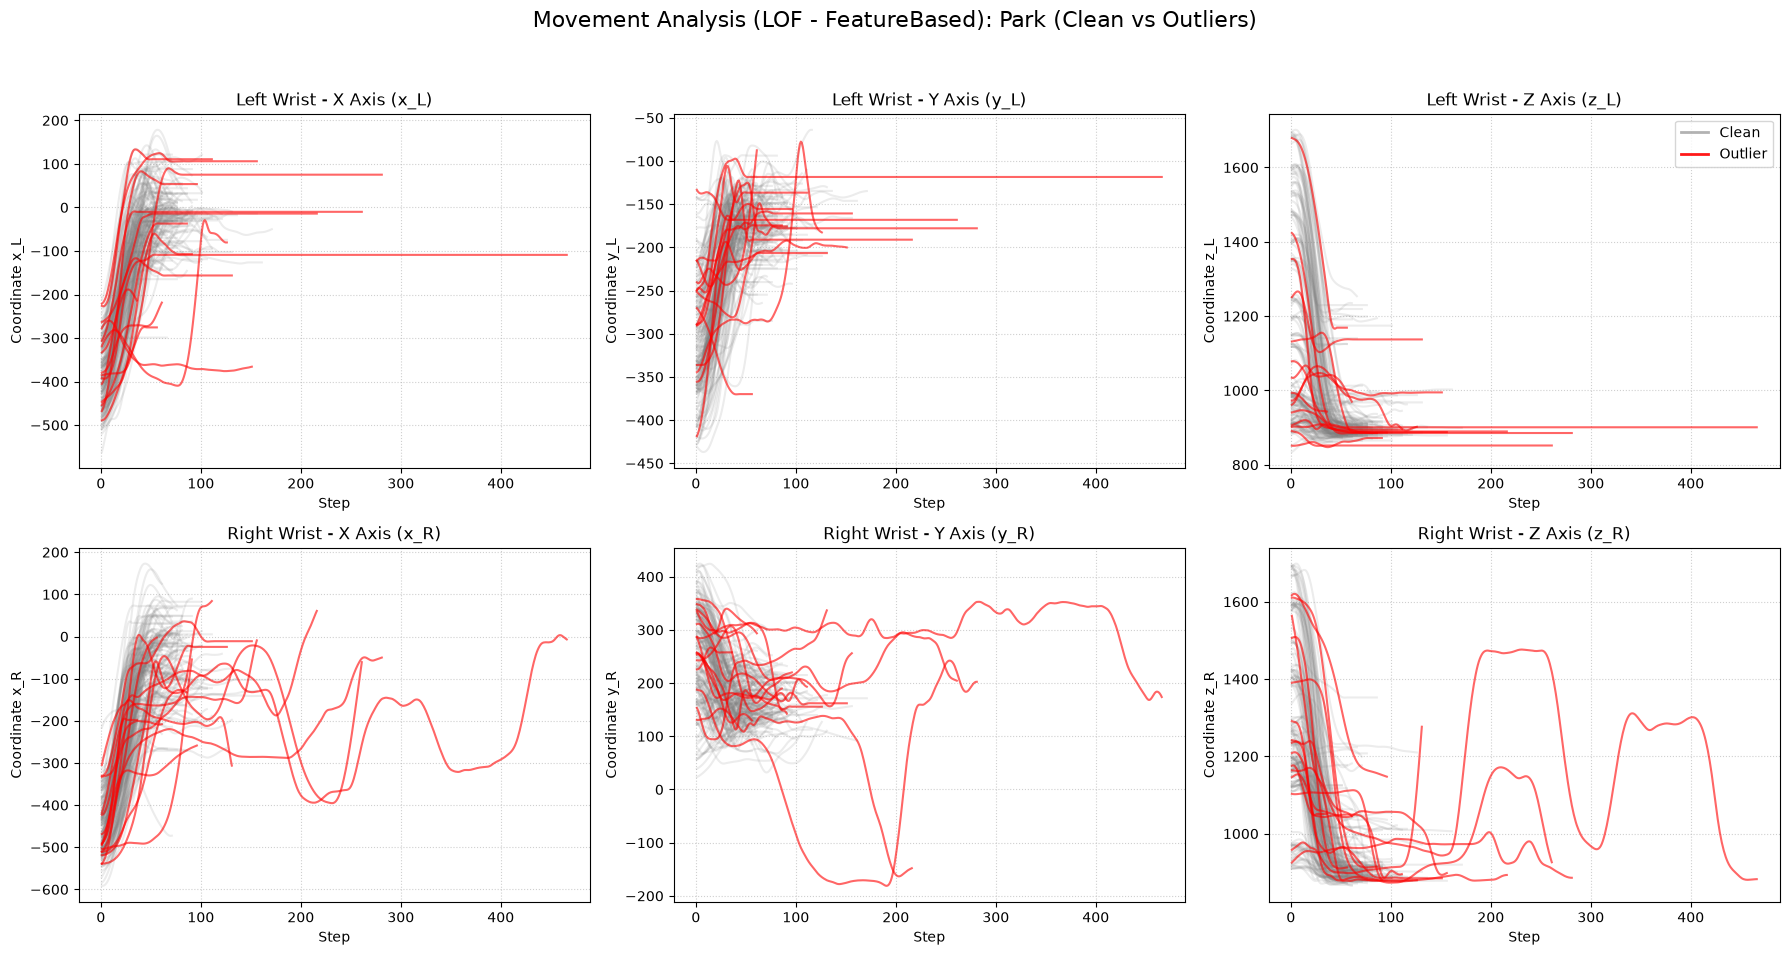

In [17]:
plot_movement_data(
    clean_data=df_clean,
    outlier_data=df_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)

In [18]:
# Limpeza: remover coluna auxiliar
df.drop(columns=['temp_key'], inplace=True)